# Applied Statistics: Iris Dataset Analysis

## Problems Overview

Below are the 4 probelms that need to be solved

### Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### Problem 2: Correlation Between Petal Length and Petal Width

Investigate the relationship between petal_length and petal_width in the Iris dataset.

1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
3. Calculate the Pearson correlation coefficient separately for each of the three species.
4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

### Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their petal_length and petal_width.

For each pair of species:

- setosa vs versicolor
- setosa vs virginica
- versicolor vs virginica

perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using scipy.stats.
3. Use a significance level of α = 0.05 to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

### Problem 4: Comparing the Species Using ANOVA

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using scipy.stats.
3. Report the F-statistic and p-value.
4. Use a significance level of α = 0.05 to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from the t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.

## Problem Solutions

### Imports and Loading Iris Dataset

In [17]:
import sklearn as skl
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

from sklearn import datasets
from scipy.stats import norm

iris = datasets.load_iris()

In [18]:
# provides variable names for each target allowing for more efficient coding and manipulation
target = iris.target
target_names = iris.target_names
data = iris.data


### Problem 1: Exploring Petal Length

Below is the code used to solve Problem 1...

In [19]:
# Extract Petal Length for all 150 flowers
petal_length = data[:, 2]

In [20]:
# Create folder for saving figures if it doesn't exist
os.makedirs("Histograms", exist_ok=True)

In [21]:
# Problem 1: Part 1
# Histogram of all petal lengths with normal curve

# Calculate mean and standard deviation
mean_length = np.mean(petal_length)
std_length = np.std(petal_length)
print(mean_length, std_length)

3.7580000000000005 1.759404065775303


In [22]:
# Create x-values for the normal distribution curve
x = np.linspace(petal_length.min(), petal_length.max(), 300)

# Calculate normal probability density
normal_curve = norm.pdf(x, mean_length, std_length)

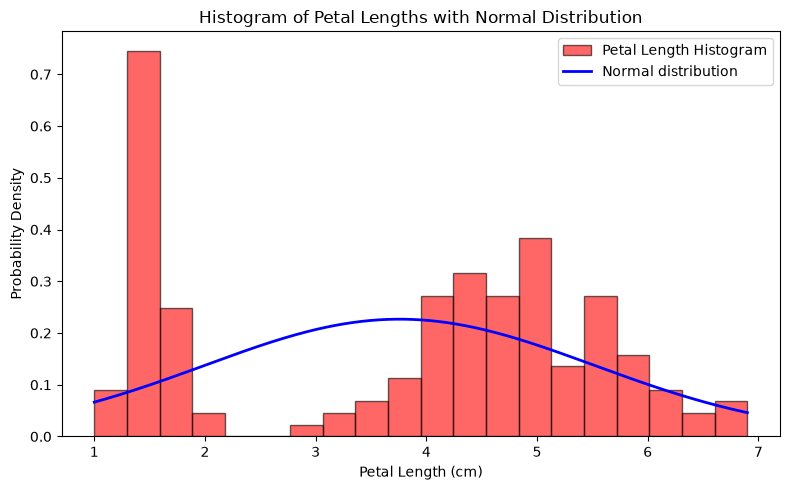

In [23]:
# Problem 1: Part 2

# Plot Histogram
plt.figure(figsize=(8, 5))
plt.hist(
    petal_length,
    bins=20,
    density=True,
    color="red",
    edgecolor="black",
    alpha=0.6,
    label="Petal Length Histogram"
)

# Superimpose normal distribution
plt.plot(
    x,
    normal_curve,
    color="blue",
    linewidth=2,
    label="Normal distribution"
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Probability Density")
plt.title("Histogram of Petal Lengths with Normal Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(
    "Histograms/Petal Length Normal Distribution.png",
    dpi=300
)
plt.show()

In [24]:
# Problem 1: Part 3

# Boolean index to select the petal length of each species
setosa_petal_length = data[target == 0, 2]
versicolor_petal_length = data[target == 1, 2]
virginica_petal_length = data[target == 2, 2]

In [26]:
# Store each species' name and petal lengths, assign a colour to each for histogram differentiation
species_data = [
    ("Setosa", setosa_petal_length, "green"),
    ("Versicolor", versicolor_petal_length, "yellow"),
    ("Virginica", virginica_petal_length, "blue")
]

# Calculate and print the mean and standard deviation
for species_name, lengths, species_color in species_data:
    mean_length = np.mean(lengths)
    std_length = np.std(lengths)
    
    print(f"{species_name}: mean = {mean_length:.2f}, std = {std_length:.2f}")

Setosa: mean = 1.46, std = 0.17
Versicolor: mean = 4.26, std = 0.47
Virginica: mean = 5.55, std = 0.55


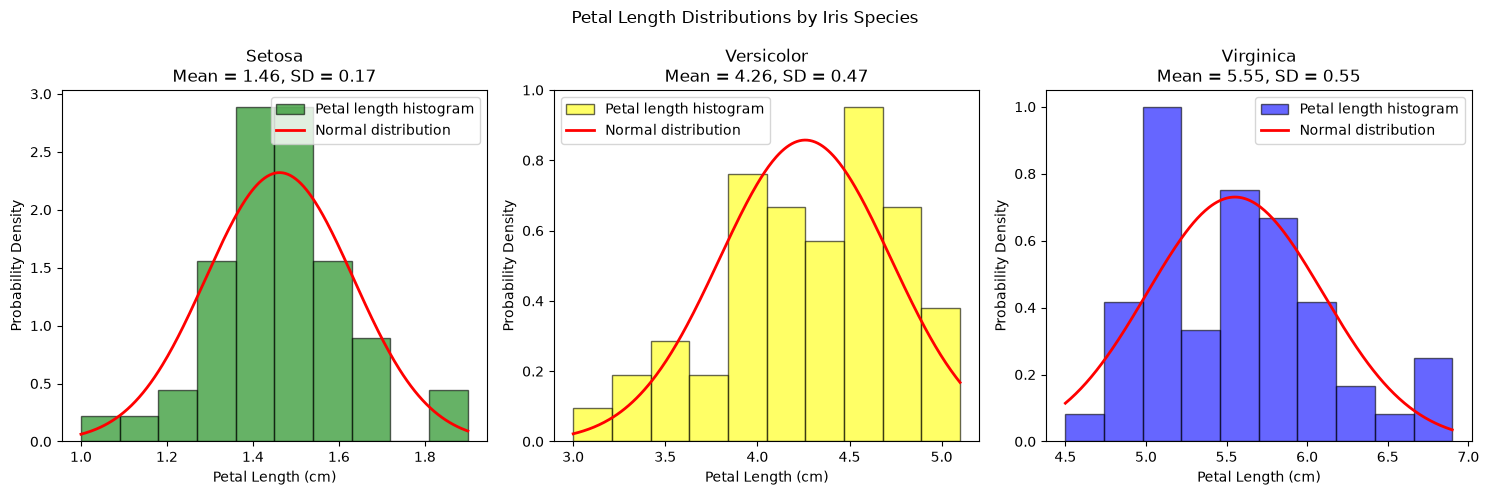

In [31]:
# Create three separate plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (species_name, lengths, species_color) in zip(axes, species_data):

    # Calculate mean and standard deviation for this species
    mean_length = np.mean(lengths)
    std_length = np.std(lengths)

    # Generate x-values and calculate normal distribution
    x = np.linspace(lengths.min(), lengths.max(), 300)
    normal_curve = norm.pdf(x, mean_length, std_length)

    # Plot histogram
    ax.hist(
        lengths,
        bins=10,
        density=True,
        color=species_color,
        edgecolor="black",
        alpha=0.6,
        label="Petal length histogram"
    )

    # Superimpose normal distribution
    ax.plot(
        x,
        normal_curve,
        color="red",
        linewidth=2,
        label="Normal distribution"
    )

    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Probability Density")
    ax.set_title(
        f"{species_name}\nMean = {mean_length:.2f}, "
        f"SD = {std_length:.2f}"
    )
    ax.legend()

fig.suptitle("Petal Length Distributions by Iris Species")
plt.tight_layout()
plt.savefig(
    "Histograms/Petal Length Distributions by Species.png",
    dpi=300
)
plt.show()


### Problem 2: Correlation Between Petal Length and Petal Width

Below is the code used to solve Problem 2...

### Problem 3: Comparing Species Using t-Tests

Below is the code used to solve Problem 3...

### Problem 4: Comparing the Species Using ANOVA

Below is the code used to solve Problem 4...